In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras.models import load_model

# Thiết lập hiển thị
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Khởi tạo Time Series Cross-Validation thành công!")

Khởi tạo Time Series Cross-Validation thành công!


In [2]:
train = pd.read_csv("../data/processed/train.csv")

print("Kích thước Train:", train.shape)
print("Khoảng thời gian:", train["step"].min(), "-", train["step"].max())

print("\nSố giao dịch theo nhãn:")
print(train["fraud"].value_counts())

print("\nTỷ lệ gian lận:")
print(train["fraud"].mean() * 100, "%")

Kích thước Train: (396332, 10)
Khoảng thời gian: 0 - 125

Số giao dịch theo nhãn:
fraud
0    391292
1      5040
Name: count, dtype: int64

Tỷ lệ gian lận:
1.2716611325858118 %


In [3]:
# Khai báo 4 fold theo thứ tự thời gian
folds = [
    {
        "fold": 1,
        "train_start": 0,
        "train_end": 44,
        "val_start": 45,
        "val_end": 64
    },
    {
        "fold": 2,
        "train_start": 0,
        "train_end": 64,
        "val_start": 65,
        "val_end": 84
    },
    {
        "fold": 3,
        "train_start": 0,
        "train_end": 84,
        "val_start": 85,
        "val_end": 104
    },
    {
        "fold": 4,
        "train_start": 0,
        "train_end": 104,
        "val_start": 105,
        "val_end": 125
    }
]

print("Đã khai báo 4 fold theo thời gian.")

Đã khai báo 4 fold theo thời gian.


In [4]:
fold_summary = []

for fold in folds:

    train_fold = train[
        train["step"].between(
            fold["train_start"], fold["train_end"]
        )
    ]

    val_fold = train[
        train["step"].between(
            fold["val_start"], fold["val_end"]
        )
    ]

    fold_summary.append({
        "Fold": fold["fold"],
        "Train steps": f'{fold["train_start"]}-{fold["train_end"]}',
        "Validation steps": f'{fold["val_start"]}-{fold["val_end"]}',
        "Train rows": len(train_fold),
        "Train fraud": int(train_fold["fraud"].sum()),
        "Validation rows": len(val_fold),
        "Validation fraud": int(val_fold["fraud"].sum()),
        "Validation fraud rate (%)": val_fold["fraud"].mean() * 100
    })

fold_summary_df = pd.DataFrame(fold_summary)

display(fold_summary_df)

,Fold,Train steps,Validation steps,Train rows,Train fraud,Validation rows,Validation fraud,Validation fraud rate (%)
0,1,0-44,45-64,125284,1800,62448,800,1.2811
1,2,0-64,65-84,187732,2600,65857,800,1.2148
2,3,0-84,85-104,253589,3400,68539,800,1.1672
3,4,0-104,105-125,322128,4200,74204,840,1.1320


In [5]:

# Khai báo các nhóm đặc trưng
numeric_features = ["step", "amount"]

categorical_features = [
    "age",
    "gender",
    "merchant",
    "category"
]

def prepare_fold_data(train_fold, val_fold):

    # Tách đặc trưng và nhãn
    X_train_raw = train_fold[
        numeric_features + categorical_features
    ].copy()

    X_val_raw = val_fold[
        numeric_features + categorical_features
    ].copy()

    y_train = train_fold["fraud"].to_numpy()
    y_val = val_fold["fraud"].to_numpy()

    # 1. Dữ liệu gốc cho Random Forest và XGBoost
    X_train_tree_num = X_train_raw[numeric_features].copy()
    X_val_tree_num = X_val_raw[numeric_features].copy()

    # 2. Dữ liệu log1p cho IF, Autoencoder và ANN
    X_train_scaled_num = X_train_raw[numeric_features].copy()
    X_val_scaled_num = X_val_raw[numeric_features].copy()

    X_train_scaled_num["amount"] = np.log1p(
        X_train_scaled_num["amount"]
    )

    X_val_scaled_num["amount"] = np.log1p(
        X_val_scaled_num["amount"]
    )

    # 3. One-Hot Encoding
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )

    X_train_cat = encoder.fit_transform(
        X_train_raw[categorical_features]
    )

    X_val_cat = encoder.transform(
        X_val_raw[categorical_features]
    )

    # 4. Dữ liệu cho Random Forest và XGBoost
    X_train_tree = np.hstack([
        X_train_tree_num.to_numpy(),
        X_train_cat
    ])

    X_val_tree = np.hstack([
        X_val_tree_num.to_numpy(),
        X_val_cat
    ])

    # 5. Chuẩn hóa dữ liệu cho IF, Autoencoder và ANN
    scaler = StandardScaler()

    X_train_num_scaled = scaler.fit_transform(
        X_train_scaled_num
    )

    X_val_num_scaled = scaler.transform(
        X_val_scaled_num
    )

    X_train_scaled = np.hstack([
        X_train_num_scaled,
        X_train_cat
    ])

    X_val_scaled = np.hstack([
        X_val_num_scaled,
        X_val_cat
    ])

    return (
        X_train_tree,
        X_val_tree,
        X_train_scaled,
        X_val_scaled,
        y_train,
        y_val,
        encoder,
        scaler
    )

print("Đã khai báo hàm tiền xử lý dữ liệu cho từng Fold.")


Đã khai báo hàm tiền xử lý dữ liệu cho từng Fold.


In [6]:
# Lấy dữ liệu Fold 1
fold_1 = folds[0]

train_fold_1 = train[
    train["step"].between(
        fold_1["train_start"],
        fold_1["train_end"]
    )
].copy()

val_fold_1 = train[
    train["step"].between(
        fold_1["val_start"],
        fold_1["val_end"]
    )
].copy()

# Tiền xử lý
(
    X_train_tree,
    X_val_tree,
    X_train_scaled,
    X_val_scaled,
    y_train_fold,
    y_val_fold,
    encoder_fold,
    scaler_fold
) = prepare_fold_data(train_fold_1, val_fold_1)

# Kiểm tra kích thước
print("Dữ liệu chưa chuẩn hóa:")
print("X_train:", X_train_tree.shape)
print("X_val:", X_val_tree.shape)

print("\nDữ liệu đã chuẩn hóa:")
print("X_train:", X_train_scaled.shape)
print("X_val:", X_val_scaled.shape)

print("\nSố đặc trưng One-Hot:", len(encoder_fold.get_feature_names_out()))
print("Số nhãn Train:", len(y_train_fold))
print("Số nhãn Validation:", len(y_val_fold))

Dữ liệu chưa chuẩn hóa:
X_train: (125284, 79)
X_val: (62448, 79)

Dữ liệu đã chuẩn hóa:
X_train: (125284, 79)
X_val: (62448, 79)

Số đặc trưng One-Hot: 77
Số nhãn Train: 125284
Số nhãn Validation: 62448


In [7]:
if_results = []

for fold in folds:

    fold_number = fold["fold"]

    print(f"\nĐang xử lý Fold {fold_number}...")

    # Chia dữ liệu
    train_fold = train[
        train["step"].between(
            fold["train_start"], fold["train_end"]
        )
    ].copy()

    val_fold = train[
        train["step"].between(
            fold["val_start"], fold["val_end"]
        )
    ].copy()

    # Tiền xử lý riêng cho Fold
    (
        X_train_tree,
        X_val_tree,
        X_train_scaled,
        X_val_scaled,
        y_train_fold,
        y_val_fold,
        encoder_fold,
        scaler_fold
    ) = prepare_fold_data(train_fold, val_fold)

    # Chỉ lấy giao dịch bình thường để huấn luyện
    X_train_normal = X_train_scaled[y_train_fold == 0]

    # Khởi tạo Isolation Forest
    model = IsolationForest(
        n_estimators=200,
        max_samples="auto",
        contamination="auto",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    # Huấn luyện
    model.fit(X_train_normal)

    # Điểm bất thường: điểm càng cao càng đáng nghi
    anomaly_scores = -model.decision_function(X_val_scaled)

    # Dự đoán theo ngưỡng mặc định
    y_pred = (model.predict(X_val_scaled) == -1).astype(int)

    # Đánh giá
    if_results.append({
        "Fold": fold_number,
        "PR-AUC": average_precision_score(
            y_val_fold, anomaly_scores
        ),
        "Precision": precision_score(
            y_val_fold, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_fold, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_fold, y_pred, zero_division=0
        )
    })

    print(f"Fold {fold_number} hoàn thành.")

# Tổng hợp kết quả
if_cv_results = pd.DataFrame(if_results)

display(if_cv_results.round(4))


Đang xử lý Fold 1...
Fold 1 hoàn thành.

Đang xử lý Fold 2...
Fold 2 hoàn thành.

Đang xử lý Fold 3...
Fold 3 hoàn thành.

Đang xử lý Fold 4...
Fold 4 hoàn thành.


,Fold,PR-AUC,Precision,Recall,F1-score
0,1,0.0465,0.0416,0.2025,0.0690
1,2,0.0456,0.0398,0.2037,0.0667
2,3,0.0497,0.0560,0.2400,0.0908
3,4,0.0391,0.0236,0.1131,0.0391


In [8]:
metrics = ["PR-AUC", "Precision", "Recall", "F1-score"]

if_cv_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [
        if_cv_results[col].mean()
        for col in metrics
    ],
    "Std": [
        if_cv_results[col].std()
        for col in metrics
    ]
})

if_cv_summary["Mean ± Std"] = if_cv_summary.apply(
    lambda row: f'{row["Mean"]:.4f} ± {row["Std"]:.4f}',
    axis=1
)

display(if_cv_summary)

,Metric,Mean,Std,Mean ± Std
0,PR-AUC,0.0452,0.0044,0.0452 ± 0.0044
1,Precision,0.0403,0.0133,0.0403 ± 0.0133
2,Recall,0.1898,0.0540,0.1898 ± 0.0540
3,F1-score,0.0664,0.0212,0.0664 ± 0.0212


In [9]:
os.makedirs("../results", exist_ok=True)

if_cv_results.to_csv(
    "../results/isolation_forest_time_series_cv.csv",
    index=False
)

if_cv_summary.to_csv(
    "../results/isolation_forest_time_series_cv_summary.csv",
    index=False
)

print("Đã lưu kết quả Cross-Validation của Isolation Forest.")

Đã lưu kết quả Cross-Validation của Isolation Forest.


In [10]:
rf_results = []

for fold in folds:

    fold_number = fold["fold"]

    print(f"\nĐang xử lý Fold {fold_number}...")

    # Chia dữ liệu
    train_fold = train[
        train["step"].between(
            fold["train_start"], fold["train_end"]
        )
    ].copy()

    val_fold = train[
        train["step"].between(
            fold["val_start"], fold["val_end"]
        )
    ].copy()

    # Tiền xử lý riêng cho Fold
    (
        X_train_tree,
        X_val_tree,
        X_train_scaled,
        X_val_scaled,
        y_train_fold,
        y_val_fold,
        encoder_fold,
        scaler_fold
    ) = prepare_fold_data(train_fold, val_fold)

    # Tính trọng số lớp
    class_weight_ratio = (
        (y_train_fold == 0).sum() /
        (y_train_fold == 1).sum()
    )

    # Khởi tạo Random Forest
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    # Huấn luyện
    model.fit(X_train_tree, y_train_fold)

    # Xác suất gian lận
    y_proba = model.predict_proba(X_val_tree)[:, 1]

    # Dự đoán tại ngưỡng 0.5
    y_pred = (y_proba >= 0.5).astype(int)

    # Đánh giá
    rf_results.append({
        "Fold": fold_number,
        "PR-AUC": average_precision_score(
            y_val_fold, y_proba
        ),
        "Precision": precision_score(
            y_val_fold, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_fold, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_fold, y_pred, zero_division=0
        )
    })

    print(f"Fold {fold_number} hoàn thành.")

# Tổng hợp kết quả
rf_cv_results = pd.DataFrame(rf_results)

display(rf_cv_results.round(4))


Đang xử lý Fold 1...
Fold 1 hoàn thành.

Đang xử lý Fold 2...
Fold 2 hoàn thành.

Đang xử lý Fold 3...
Fold 3 hoàn thành.

Đang xử lý Fold 4...
Fold 4 hoàn thành.


,Fold,PR-AUC,Precision,Recall,F1-score
0,1,0.8534,0.5115,0.9150,0.6562
1,2,0.8685,0.5300,0.9062,0.6688
2,3,0.8594,0.5536,0.9238,0.6923
3,4,0.8701,0.5158,0.9310,0.6638


In [11]:
# Tính giá trị trung bình và độ lệch chuẩn giữa 4 fold
metrics = ["PR-AUC", "Precision", "Recall", "F1-score"]

rf_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [rf_cv_results[col].mean() for col in metrics],
    "Std": [rf_cv_results[col].std() for col in metrics]
})

display(rf_summary.round(4))

# Lưu kết quả từng fold và bảng tổng hợp
rf_cv_results.to_csv(
    "../results/random_forest_time_series_cv.csv",
    index=False
)

rf_summary.to_csv(
    "../results/random_forest_time_series_cv_summary.csv",
    index=False
)

print("Đã lưu kết quả Time Series CV của Random Forest.")

,Metric,Mean,Std
0,PR-AUC,0.8628,0.0079
1,Precision,0.5277,0.0189
2,Recall,0.9190,0.0107
3,F1-score,0.6703,0.0155


Đã lưu kết quả Time Series CV của Random Forest.


In [12]:
xgb_results = []

for fold in folds:
    fold_number = fold["fold"]

    train_fold = train[
        train["step"].between(fold["train_start"], fold["train_end"])
    ].copy()

    val_fold = train[
        train["step"].between(fold["val_start"], fold["val_end"])
    ].copy()

    (
        X_train_tree, X_val_tree,
        X_train_scaled, X_val_scaled,
        y_train_fold, y_val_fold,
        encoder_fold, scaler_fold
    ) = prepare_fold_data(train_fold, val_fold)

    # Tính trọng số lớp theo từng fold
    scale_pos_weight = (
        (y_train_fold == 0).sum() / (y_train_fold == 1).sum()
    )

    model = XGBClassifier(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="aucpr",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train_tree, y_train_fold)

    y_proba = model.predict_proba(X_val_tree)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    xgb_results.append({
        "Fold": fold_number,
        "PR-AUC": average_precision_score(y_val_fold, y_proba),
        "Precision": precision_score(y_val_fold, y_pred, zero_division=0),
        "Recall": recall_score(y_val_fold, y_pred, zero_division=0),
        "F1-score": f1_score(y_val_fold, y_pred, zero_division=0)
    })

    print(f"Đã hoàn thành XGBoost Fold {fold_number}")

xgb_cv_results = pd.DataFrame(xgb_results)

display(xgb_cv_results.round(4))

Đã hoàn thành XGBoost Fold 1
Đã hoàn thành XGBoost Fold 2
Đã hoàn thành XGBoost Fold 3
Đã hoàn thành XGBoost Fold 4


,Fold,PR-AUC,Precision,Recall,F1-score
0,1,0.8800,0.4888,0.9250,0.6396
1,2,0.8918,0.5982,0.9025,0.7195
2,3,0.8907,0.5082,0.9350,0.6585
3,4,0.8842,0.5140,0.9393,0.6644


In [13]:
# Tính Mean và Std giữa 4 fold
metrics = ["PR-AUC", "Precision", "Recall", "F1-score"]

xgb_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [xgb_cv_results[col].mean() for col in metrics],
    "Std": [xgb_cv_results[col].std() for col in metrics]
})

display(xgb_summary.round(4))

# Lưu kết quả từng fold và bảng tổng hợp
xgb_cv_results.to_csv(
    "../results/xgboost_time_series_cv.csv",
    index=False
)

xgb_summary.to_csv(
    "../results/xgboost_time_series_cv_summary.csv",
    index=False
)

print("Đã lưu kết quả Time Series CV của XGBoost.")

,Metric,Mean,Std
0,PR-AUC,0.8867,0.0056
1,Precision,0.5273,0.0485
2,Recall,0.9254,0.0164
3,F1-score,0.6705,0.0343


Đã lưu kết quả Time Series CV của XGBoost.


In [14]:
ae_results = []

for fold in folds:
    fold_number = fold["fold"]

    train_fold = train[
        train["step"].between(fold["train_start"], fold["train_end"])
    ].copy()

    val_fold = train[
        train["step"].between(fold["val_start"], fold["val_end"])
    ].copy()

    (
        X_train_tree, X_val_tree,
        X_train_scaled, X_val_scaled,
        y_train_fold, y_val_fold,
        encoder_fold, scaler_fold
    ) = prepare_fold_data(train_fold, val_fold)

    # Tách 10% thời gian cuối của Train fold làm tập hiệu chỉnh ngưỡng
    calibration_start = train_fold["step"].quantile(0.90)

    calibration_mask = train_fold["step"] >= calibration_start

    X_calibration = X_train_scaled[
        calibration_mask.values & (y_train_fold == 0)
    ]

    X_fit = X_train_scaled[
        (~calibration_mask).values & (y_train_fold == 0)
    ]

    # Xây dựng Autoencoder
    input_dim = X_train_scaled.shape[1]

    inputs = tf.keras.Input(shape=(input_dim,))

    x = tf.keras.layers.Dense(64, activation="relu")(inputs)
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    x = tf.keras.layers.Dense(16, activation="relu")(x)
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)

    outputs = tf.keras.layers.Dense(input_dim, activation="linear")(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(optimizer="adam", loss="mse")

    # Huấn luyện chỉ trên giao dịch bình thường thuộc phần Fit
    model.fit(
        X_fit,
        X_fit,
        epochs=4,
        batch_size=256,
        shuffle=True,
        verbose=0
    )

    # Tính lỗi tái tạo trên tập Calibration bình thường
    X_calibration_reconstructed = model.predict(
        X_calibration,
        verbose=0
    )

    calibration_errors = np.mean(
        np.square(X_calibration - X_calibration_reconstructed),
        axis=1
    )

    # Chọn ngưỡng từ tập Calibration
    threshold = np.percentile(calibration_errors, 95)

    # Đánh giá trên Validation fold
    X_val_reconstructed = model.predict(
        X_val_scaled,
        verbose=0
    )

    reconstruction_errors = np.mean(
        np.square(X_val_scaled - X_val_reconstructed),
        axis=1
    )

    y_scores = reconstruction_errors
    y_pred = (y_scores >= threshold).astype(int)

    ae_results.append({
        "Fold": fold_number,
        "PR-AUC": average_precision_score(y_val_fold, y_scores),
        "Precision": precision_score(y_val_fold, y_pred, zero_division=0),
        "Recall": recall_score(y_val_fold, y_pred, zero_division=0),
        "F1-score": f1_score(y_val_fold, y_pred, zero_division=0),
        "Threshold": threshold
    })

    print(f"Đã hoàn thành Autoencoder Fold {fold_number}")

ae_cv_results = pd.DataFrame(ae_results)

display(ae_cv_results.round(4))

Đã hoàn thành Autoencoder Fold 1
Đã hoàn thành Autoencoder Fold 2
Đã hoàn thành Autoencoder Fold 3
Đã hoàn thành Autoencoder Fold 4


,Fold,PR-AUC,Precision,Recall,F1-score,Threshold
0,1,0.3077,0.1436,0.7238,0.2397,0.0121
1,2,0.2819,0.1308,0.7025,0.2205,0.0075
2,3,0.3285,0.1521,0.7525,0.2531,0.0098
3,4,0.3123,0.1674,0.9226,0.2833,0.0087


In [15]:
metrics = ["PR-AUC", "Precision", "Recall", "F1-score"]

ae_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [ae_cv_results[col].mean() for col in metrics],
    "Std": [ae_cv_results[col].std() for col in metrics]
})

display(ae_summary.round(4))

# Lưu kết quả từng fold và bảng tổng hợp
ae_cv_results.to_csv(
    "../results/autoencoder_time_series_cv.csv",
    index=False
)

ae_summary.to_csv(
    "../results/autoencoder_time_series_cv_summary.csv",
    index=False
)

print("Đã lưu kết quả Time Series CV của Autoencoder.")

,Metric,Mean,Std
0,PR-AUC,0.3076,0.0193
1,Precision,0.1485,0.0153
2,Recall,0.7753,0.1003
3,F1-score,0.2492,0.0264


Đã lưu kết quả Time Series CV của Autoencoder.


In [16]:
ann_results = []

for fold in folds:
    fold_number = fold["fold"]

    train_fold = train[
        train["step"].between(fold["train_start"], fold["train_end"])
    ].copy()

    val_fold = train[
        train["step"].between(fold["val_start"], fold["val_end"])
    ].copy()

    (
        X_train_tree, X_val_tree,
        X_train_scaled, X_val_scaled,
        y_train_fold, y_val_fold,
        encoder_fold, scaler_fold
    ) = prepare_fold_data(train_fold, val_fold)

    # Tính class weight riêng cho từng fold
    n_normal = (y_train_fold == 0).sum()
    n_fraud = (y_train_fold == 1).sum()

    class_weight = {
        0: len(y_train_fold) / (2 * n_normal),
        1: len(y_train_fold) / (2 * n_fraud)
    }

    # Xây dựng ANN
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE)

    inputs = tf.keras.Input(shape=(X_train_scaled.shape[1],))

    x = tf.keras.layers.Dense(128, activation="relu")(inputs)
    x = tf.keras.layers.Dropout(0.3)(x)

    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    x = tf.keras.layers.Dense(32, activation="relu")(x)

    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["AUC", "Precision", "Recall"]
    )

    # Huấn luyện ANN
    model.fit(
        X_train_scaled,
        y_train_fold,
        epochs=13,
        batch_size=256,
        class_weight=class_weight,
        shuffle=True,
        verbose=0
    )

    # Dự đoán trên Validation fold
    y_proba = model.predict(
        X_val_scaled,
        verbose=0
    ).ravel()

    y_pred = (y_proba >= 0.5).astype(int)

    ann_results.append({
        "Fold": fold_number,
        "PR-AUC": average_precision_score(y_val_fold, y_proba),
        "Precision": precision_score(y_val_fold, y_pred, zero_division=0),
        "Recall": recall_score(y_val_fold, y_pred, zero_division=0),
        "F1-score": f1_score(y_val_fold, y_pred, zero_division=0)
    })

    print(f"Đã hoàn thành ANN Fold {fold_number}")

ann_cv_results = pd.DataFrame(ann_results)

display(ann_cv_results.round(4))


Đã hoàn thành ANN Fold 1
Đã hoàn thành ANN Fold 2
Đã hoàn thành ANN Fold 3
Đã hoàn thành ANN Fold 4


,Fold,PR-AUC,Precision,Recall,F1-score
0,1,0.8722,0.3745,0.9362,0.5350
1,2,0.9005,0.4122,0.9512,0.5752
2,3,0.9066,0.2804,0.9838,0.4364
3,4,0.9038,0.2668,0.9905,0.4204


In [17]:
metrics = ["PR-AUC", "Precision", "Recall", "F1-score"]

ann_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [ann_cv_results[col].mean() for col in metrics],
    "Std": [ann_cv_results[col].std() for col in metrics]
})

display(ann_summary.round(4))

# Lưu kết quả từng fold và bảng tổng hợp
ann_cv_results.to_csv(
    "../results/ann_time_series_cv.csv",
    index=False
)

ann_summary.to_csv(
    "../results/ann_time_series_cv_summary.csv",
    index=False
)

print("Đã lưu kết quả Time Series CV của ANN.")

,Metric,Mean,Std
0,PR-AUC,0.8958,0.0159
1,Precision,0.3335,0.0711
2,Recall,0.9654,0.0259
3,F1-score,0.4917,0.0753


Đã lưu kết quả Time Series CV của ANN.


In [18]:
ann_cv_results.to_csv(
    "../results/ann_time_series_cv.csv",
    index=False
)

ann_summary.to_csv(
    "../results/ann_time_series_cv_summary.csv",
    index=False
)

print("Đã lưu kết quả Time Series CV của ANN.")

Đã lưu kết quả Time Series CV của ANN.


In [19]:
# Đọc kết quả từng fold của Isolation Forest
if_cv_results = pd.read_csv(
    "../results/isolation_forest_time_series_cv.csv"
)

# Tính Mean và Std
metrics = ["PR-AUC", "Precision", "Recall", "F1-score"]

if_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [if_cv_results[col].mean() for col in metrics],
    "Std": [if_cv_results[col].std() for col in metrics]
})

display(if_summary.round(4))

,Metric,Mean,Std
0,PR-AUC,0.0452,0.0044
1,Precision,0.0403,0.0133
2,Recall,0.1898,0.0540
3,F1-score,0.0664,0.0212


In [20]:
# Tổng hợp Mean và Std của 5 mô hình
cv_summaries = {
    "Isolation Forest": if_summary,
    "Random Forest": rf_summary,
    "XGBoost": xgb_summary,
    "Autoencoder": ae_summary,
    "ANN": ann_summary
}

comparison_rows = []

for model_name, summary in cv_summaries.items():
    row = {"Model": model_name}

    for _, metric_row in summary.iterrows():
        metric = metric_row["Metric"]
        mean = metric_row["Mean"]
        std = metric_row["Std"]

        row[f"{metric} Mean"] = mean
        row[f"{metric} Std"] = std

    comparison_rows.append(row)

cv_comparison = pd.DataFrame(comparison_rows)

display(cv_comparison.round(4))

# Lưu bảng so sánh tổng hợp
cv_comparison.to_csv(
    "../results/time_series_cv_comparison.csv",
    index=False
)

print("Đã lưu bảng so sánh Time Series CV của 5 mô hình.")

,Model,PR-AUC Mean,PR-AUC Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1-score Mean,F1-score Std
0,Isolation Forest,0.0452,0.0044,0.0403,0.0133,0.1898,0.0540,0.0664,0.0212
1,Random Forest,0.8628,0.0079,0.5277,0.0189,0.9190,0.0107,0.6703,0.0155
2,XGBoost,0.8867,0.0056,0.5273,0.0485,0.9254,0.0164,0.6705,0.0343
3,Autoencoder,0.3076,0.0193,0.1485,0.0153,0.7753,0.1003,0.2492,0.0264
4,ANN,0.8958,0.0159,0.3335,0.0711,0.9654,0.0259,0.4917,0.0753


Đã lưu bảng so sánh Time Series CV của 5 mô hình.


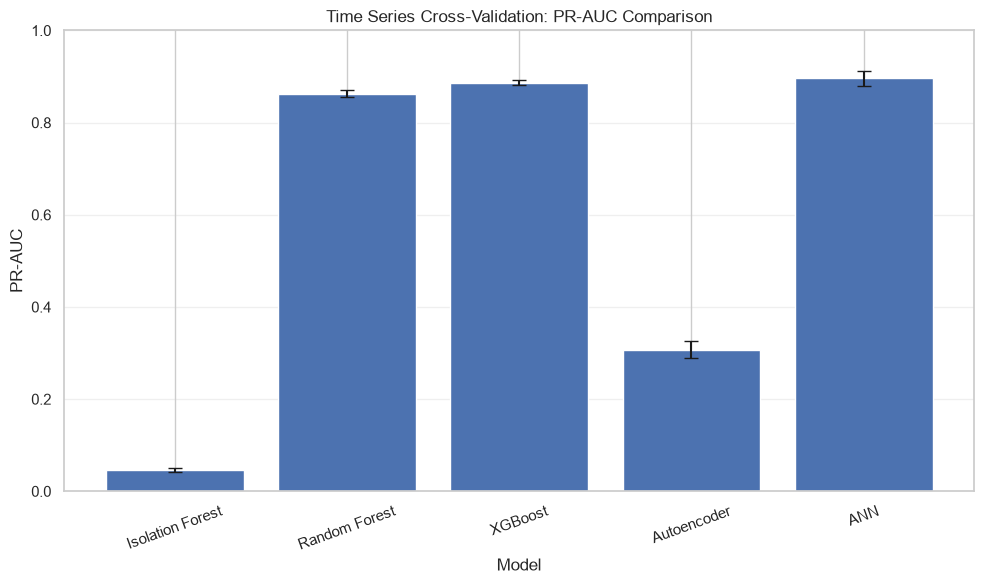

In [21]:
plt.figure(figsize=(10, 6))

plt.bar(
    cv_comparison["Model"],
    cv_comparison["PR-AUC Mean"],
    yerr=cv_comparison["PR-AUC Std"],
    capsize=5
)

plt.title("Time Series Cross-Validation: PR-AUC Comparison")
plt.xlabel("Model")
plt.ylabel("PR-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "../results/time_series_cv_pr_auc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

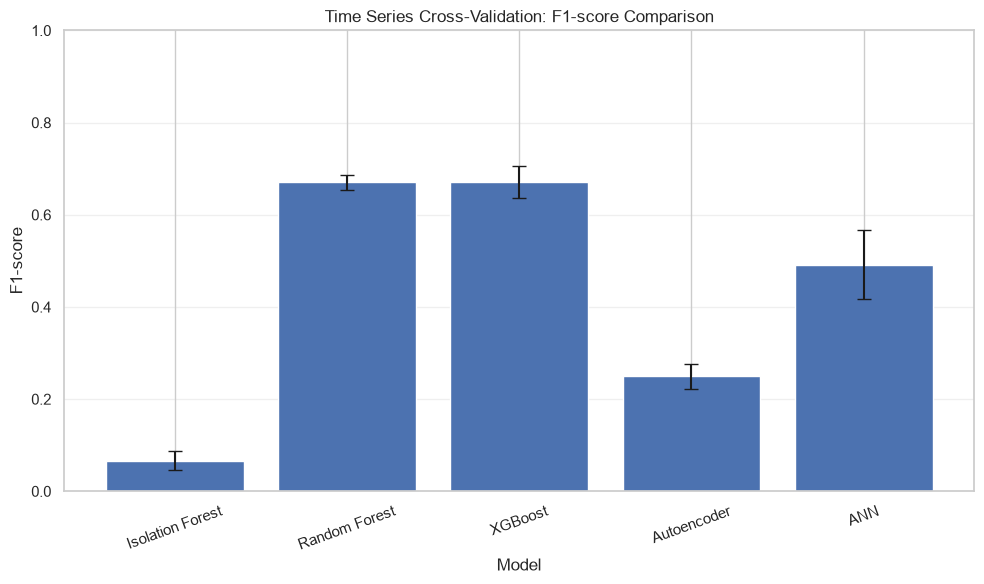

In [22]:
plt.figure(figsize=(10, 6))

plt.bar(
    cv_comparison["Model"],
    cv_comparison["F1-score Mean"],
    yerr=cv_comparison["F1-score Std"],
    capsize=5
)

plt.title("Time Series Cross-Validation: F1-score Comparison")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "../results/time_series_cv_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()